# CNW-Grass gas exchange, 5: a measured weather

**What you will learn:** give the model a measured weather, hour by hour, and compare the stand's gas exchange on a
clear and on a cloudy day.

**You need:** tutorials 1 and 2, and a little pandas. **Run time:** about 20 seconds.

**About the data.** The package ships the weather of a field experiment (`meteo_Ljutovac2002.csv`, in
`example/Vegetative_stages/inputs/`, used by CNW-Grass's own examples): every hour from December 1998 to July
1999, the air temperature, the PAR above the crop, the relative humidity, the CO₂ and the wind. It ships no
measurement of gas exchange: with your own (a canopy chamber's, a leaf's), compare them with `result.summary` or
`result.elements()` as Caribu's or ArchiSimple's tutorial 5 does.

## 1. The data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.cnwgrass.metafspm.simulation import simulate

meteo = pd.read_csv("../../Vegetative_stages/inputs/meteo_Ljutovac2002.csv")
meteo.head()

,t,Date,DOY,hour,air_temperature,PARi,soil_temperature,humidity,ambient_CO2,Wind
0,0,17/12/1998,351,12,5.2,516.222222,5.840,0.95,360,2.9
1,1,17/12/1998,351,13,5.6,549.888889,6.264,0.88,360,2.9
2,2,17/12/1998,351,14,4.8,392.777778,5.415,0.92,360,2.9
3,3,17/12/1998,351,15,3.6,157.111111,6.223,0.95,360,2.9
4,4,17/12/1998,351,16,3.5,22.444444,5.957,0.96,360,2.9


Each row is an hour: `DOY` (the day of the year), `hour` (1 to 24), `air_temperature` (°C), `PARi` (µmol m⁻² s⁻¹),
`humidity` (the relative humidity, a fraction), `ambient_CO2` (µmol mol⁻¹), `Wind` (m s⁻¹). Two days of May 1999,
a clear one and a cloudy one:

In [2]:
daily = meteo.groupby("DOY").agg(date=("Date", "first"), PAR=("PARi", "sum"), temperature=("air_temperature", "mean"),
                                 humidity=("humidity", "mean"))
may = daily.loc[121:151]
clear_day, cloudy_day = int(may["PAR"].idxmax()), int(may["PAR"].idxmin())
may.loc[[clear_day, cloudy_day]].round(1)

,date,PAR,temperature,humidity
DOY,,,,
146,26/05/1999,16889.4,16.1,0.7
140,20/05/1999,1851.7,12.2,1.0


## 2. A measured weather as input

`simulate` takes each weather variable as a number, a function of the hour, or a pandas Series indexed by hour
(interpolated between the hours). The station's hours are taken as universal time. The days are computed from 5 to
20 h:

In [3]:
def day_weather(day):
    rows = meteo[meteo["DOY"] == day].set_index("hour")
    return dict(PARi=rows["PARi"], air_temperature=rows["air_temperature"], relative_humidity=rows["humidity"],
                ambient_CO2=rows["ambient_CO2"], wind_speed=rows["Wind"])


days = {name: simulate(day_of_year=day, hours=16, start_hour=5, **day_weather(day))
        for name, day in (("clear", clear_day), ("cloudy", cloudy_day))}

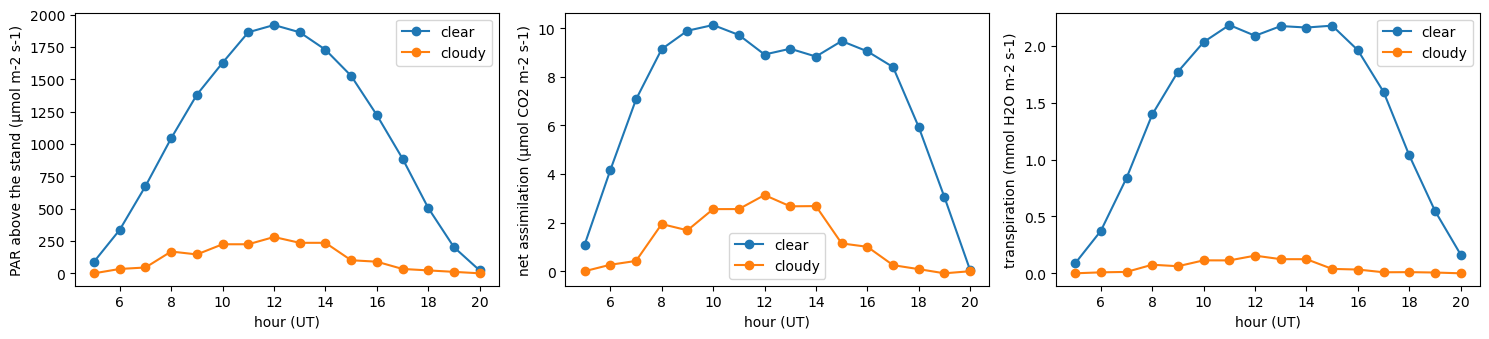

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for name, result in days.items():
    summary = result.summary
    axes[0].plot(summary["hour"], summary["PARi"], "o-", label=name)
    axes[1].plot(summary["hour"], summary["net_assimilation"], "o-", label=name)
    axes[2].plot(summary["hour"], summary["transpiration"], "o-", label=name)
for ax, label in zip(axes, ("PAR above the stand (µmol m-2 s-1)", "net assimilation (µmol CO2 m-2 s-1)",
                            "transpiration (mmol H2O m-2 s-1)")):
    ax.set_xlabel("hour (UT)"); ax.set_ylabel(label); ax.legend()
plt.tight_layout()

## 3. The days' totals

In [5]:
totals = {}
for name, result in days.items():
    summary = result.summary
    CO2 = summary["net_assimilation"].sum() * 3600 * 1e-6 * 44
    water = summary["transpiration"].sum() * 3600 * 18e-3 / 1000
    totals[name] = {"PAR (mol m-2)": summary["PARi"].sum() * 3600 / 1e6, "CO2 fixed (g m-2)": CO2,
                    "water transpired (mm)": water, "g CO2 per kg water": CO2 / water,
                    "g CO2 per mol PAR absorbed": CO2 / (summary["PAR_absorbed"].sum() * 3600 / 1e6)}
pd.DataFrame(totals).round(2)

,clear,cloudy
PAR (mol m-2),60.80,6.67
CO2 fixed (g m-2),18.06,3.22
water transpired (mm),1.46,0.06
g CO2 per kg water,12.34,55.93
g CO2 per mol PAR absorbed,1.36,2.18


**Reading the table.** The cloudy day brings much less light, and the stand fixes less CO₂, but not in proportion:
per mole of PAR absorbed it fixes more. On the clear day many leaves are light-saturated around noon and waste part
of their light; under clouds they work on the steep part of their light response (tutorial 1). The cloudy day's
water use efficiency is also higher: its air is cooler and more humid, so the leaves lose less water for the CO₂ they
take in.

## Try it yourself

1. Compute the whole month of May day by day (each day `hours=16, start_hour=5`) and plot the CO₂ fixed against
   the day's PAR. Is the relation linear?
2. The measured CO₂ is 360 ppm. Run the clear day at 410 ppm (`ambient_CO2=410.`): how much does the day's CO₂ fixed
   change?
3. Prepare a CSV of your own weather (columns `hour`, `PARi`, `air_temperature`, ...) and run the stand with it.

**Next:** `06_with_other_models.ipynb`.